
# RQ27 — Can an ensemble outperform or stabilize the best individual model?

## Scientific question

**Can combinations of the RQ26 deployment candidates improve predictive performance, adverse-regime robustness, or stability across the full R×S landscape relative to the strongest individual models?**

RQ27 consumes the **frozen RQ26 portfolios**. It does not rediscover candidates and it does not retrain any model.

For each endpoint with `K` selected individual models, RQ27 evaluates **all non-singleton subsets**:

\[
N_{\mathrm{ensemble}} = 2^K-K-1.
\]

Under the current RQ26 freeze this corresponds to **46 unique ensemble definitions** across the seven benchmark tasks, each evaluated across all 16 `R×S` cells.

The primary ensemble is **unweighted soft voting**. A secondary weighted soft vote is evaluated only when its weights can be derived entirely from the frozen **inner-validation layer**, never from outer-test performance.



## Methodological contract

### 1. Candidate pool is frozen by RQ26

RQ27 reads:

```text
results/analysis_deployment/rq26/rq26_RQ27_candidate_manifest.tsv
```

The ensemble search cannot add a model that did not survive RQ26.

### 2. Outer-test predictions are used only for retrospective evaluation

The benchmark retained mandatory per-sequence outer-test predictions for every fitted experiment.

Binary outputs contain:

```text
entity_id
sequence_uid
y_true
y_pred
score_positive
```

Multiclass outputs contain stable IDs, `y_true`, `y_pred`, and one probability column per class.

The methodological design originally specified `p_endolysin`, `p_depolymerase`, and `p_val`. RQ27 does **not** assume those literal names, because the frozen real training artifacts may serialize the VAL probability with its full biological class name (for example `p_virion_associated_lytic_enzyme`). Instead, the notebook discovers the three probability columns from each frozen file, maps them to the stored class labels, and requires that probability argmax reproduces the stored `y_pred` before any ensemble is evaluated.

RQ27 combines these already-generated probabilities. It does not refit models or optimize outer-test thresholds.

### 3. Unweighted soft voting is primary

Binary:

\[
\hat p(x)=\frac{1}{K}\sum_i p_i(x),
\qquad
\hat y=\mathbf{1}[\hat p\ge0.5].
\]

Multiclass:

\[
\hat{\mathbf p}(x)=\frac{1}{K}\sum_i\mathbf p_i(x),
\qquad
\hat y=\arg\max_c \hat p_c.
\]

### 4. Weighted voting must be leakage-safe

If the selected configuration's **validation MCC** can be recovered from `validation_metrics.tsv` / `selected_configuration.json`, define:

\[
w_i =
\frac{\max(MCC^{val}_i,0)}
{\sum_j\max(MCC^{val}_j,0)}.
\]

No outer-test metric may determine the weights.

Weighted voting is **secondary**. If the required validation information is unavailable or ambiguous, that ensemble/cell is reported as `weighted_not_estimable`; the unweighted result remains canonical.

### 5. No new bootstrap in RQ27

This notebook is a retrospective ensemble analysis over the completed benchmark. It reports matched cell-wise gains and error complementarity without launching another mass-bootstrap layer. Any final production ensemble requiring a targeted confidence interval can be bootstrapped later after RQ28 freezes the architecture.



## What “better” and “more stable” mean

RQ27 keeps the same multidimensional philosophy as RQ17/RQ26.

For every ensemble surface, we measure:

- mean MCC;
- median MCC;
- worst-case MCC;
- strict `R30/S30` MCC;
- surface range and standard deviation;
- extreme R sensitivity;
- extreme S sensitivity;
- R×S interaction RMS.

The ensemble is compared against:

1. the frozen **RQ26 performance leader**;
2. the best individual Top-K model for the same criterion;
3. the **cell-best individual Top-K model** in each matched `task × R × S` cell.

A model is never called “stable” merely because it is uniformly mediocre. Stabilization analyses are restricted to ensembles whose mean MCC remains within `0.02` of the task-best individual mean MCC.

### Error complementarity

For every candidate pair and matched outer-test cell, RQ27 quantifies:

- prediction disagreement;
- double-fault rate;
- fraction where only model A is correct;
- fraction where only model B is correct;
- pairwise oracle accuracy: fraction correct if an oracle could choose whichever member is correct;
- Jaccard overlap of the two error sets.

These diagnostics answer whether ensemble gains are supported by **genuinely complementary errors** or merely by averaging nearly identical predictors.


In [1]:

from pathlib import Path
from itertools import combinations
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    matthews_corrcoef,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 300)
pd.set_option("display.max_rows", 500)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]
COMPETITIVE_GAP = 0.02
PRIMARY_METRIC = "mcc"

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

MULTICLASS_TASKS = ["multiclass_clean"]
MULTICLASS_N_CLASSES = 3

# Known aliases are hints only. The actual probability columns are discovered
# from the frozen prediction file and validated against stored y_pred.
MULTI_PROBABILITY_ALIASES = {
    "endolysin": {
        "p_endolysin",
    },
    "depolymerase": {
        "p_depolymerase",
    },
    "val": {
        "p_val",
        "p_virion_associated_lytic_enzyme",
        "p_virion_associated_lytic_enzyme_val",
    },
}


def find_project_root(start=None):
    explicit = os.environ.get("PHAGELYSCLASS_ROOT")
    if explicit:
        root = Path(explicit).expanduser().resolve()
        if (
            (root / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file()
            and (root / "results/training_supervised").is_dir()
            and (root / "results/analysis_deployment/rq26/rq26_RQ27_candidate_manifest.tsv").is_file()
        ):
            return root
        raise FileNotFoundError(
            f"PHAGELYSCLASS_ROOT does not satisfy RQ27 project contract: {root}"
        )

    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file()
            and (candidate / "results/training_supervised").is_dir()
            and (candidate / "results/analysis_deployment/rq26/rq26_RQ27_candidate_manifest.tsv").is_file()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate PhageLysClass root with Stage12A, training_supervised, "
        "and frozen RQ26 deployment manifest."
    )


ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
TRAINING_ROOT = ROOT / "results/training_supervised"
RQ26_DIR = ROOT / "results/analysis_deployment/rq26"

RQ27_OUT = ROOT / "results/analysis_deployment/rq27"
FIG_DIR = RQ27_OUT / "figures"
RQ27_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ27_OUT:", RQ27_OUT)
print("No model training, threshold optimization, outer-test weight fitting, or bootstrap is performed.")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ27_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq27
No model training, threshold optimization, outer-test weight fitting, or bootstrap is performed.


## 1. Real-project preflight and frozen RQ26 portfolio

In [2]:

PATHS = {
    "supervised_master": STAGE12A / "supervised_master_results.tsv",
    "rq26_candidate_manifest": RQ26_DIR / "rq26_RQ27_candidate_manifest.tsv",
    "rq26_topK": RQ26_DIR / "rq26_topK_individual_candidates.tsv",
    "rq26_role_winners": RQ26_DIR / "rq26_operational_role_winners.tsv",
    "rq26_manifest": RQ26_DIR / "rq26_manifest.json",
}

preflight = pd.DataFrame([
    {"artifact": name, "path": str(path), "exists": path.is_file()}
    for name, path in PATHS.items()
])
display(preflight)

missing = preflight[~preflight["exists"]]
if len(missing):
    raise FileNotFoundError(
        "RQ27 requires completed RQ26 outputs:\n"
        + missing[["artifact", "path"]].to_string(index=False)
    )

master = pd.read_csv(PATHS["supervised_master"], sep="\t", low_memory=False)
candidate_manifest = pd.read_csv(
    PATHS["rq26_candidate_manifest"], sep="\t", low_memory=False
)
topk = pd.read_csv(PATHS["rq26_topK"], sep="\t", low_memory=False)
role_winners = pd.read_csv(PATHS["rq26_role_winners"], sep="\t", low_memory=False)
rq26_meta = json.loads(PATHS["rq26_manifest"].read_text())

required_candidate = {
    "task", "representation", "algorithm", "strategy_id", "topK_rank",
}
missing_cols = required_candidate - set(candidate_manifest.columns)
if missing_cols:
    raise KeyError(
        f"RQ26 candidate manifest missing: {sorted(missing_cols)}"
    )

assert len(master) == 2240
assert set(candidate_manifest["task"]) == set(TASK_ORDER)
assert candidate_manifest.groupby("task").size().between(2, 4).all()
assert not candidate_manifest.duplicated(
    ["task", "representation", "algorithm"]
).any()

k_by_task = candidate_manifest.groupby("task").size().reindex(TASK_ORDER)
ensemble_defs_by_task = (2 ** k_by_task) - k_by_task - 1

# Current frozen RQ26 real-data result.
expected_selected = rq26_meta.get("n_selected_candidates")
if expected_selected is not None:
    assert len(candidate_manifest) == int(expected_selected)

print("Frozen RQ26 candidates:", len(candidate_manifest))
print("K by task:")
print(k_by_task.to_string())
print("Non-singleton ensemble definitions by task:")
print(ensemble_defs_by_task.to_string())
print("Total ensemble definitions:", int(ensemble_defs_by_task.sum()))
print("REAL_PROJECT_PREFLIGHT_OK")


,artifact,path,exists
0,supervised_master,/home/david/Desktop/colabs/inta_project/phagel...,True
1,rq26_candidate_manifest,/home/david/Desktop/colabs/inta_project/phagel...,True
2,rq26_topK,/home/david/Desktop/colabs/inta_project/phagel...,True
3,rq26_role_winners,/home/david/Desktop/colabs/inta_project/phagel...,True
4,rq26_manifest,/home/david/Desktop/colabs/inta_project/phagel...,True


Frozen RQ26 candidates: 23
K by task:
task
global_easy             3
global_hard             4
global_mixed            3
subtype_endolysin       3
subtype_depolymerase    4
subtype_val             2
multiclass_clean        4
Non-singleton ensemble definitions by task:
task
global_easy              4
global_hard             11
global_mixed             4
subtype_endolysin        4
subtype_depolymerase    11
subtype_val              1
multiclass_clean        11
Total ensemble definitions: 46
REAL_PROJECT_PREFLIGHT_OK


## 2. Resolve all selected experiment directories and prediction artifacts

In [3]:

def experiment_dir(task, r, s, representation, algorithm):
    return (
        TRAINING_ROOT
        / TASK_PATHS[task]
        / f"R{r}_S{s}"
        / representation
        / algorithm
    )


artifact_rows = []

for rec in candidate_manifest.to_dict("records"):
    for r in R_LEVELS:
        for s in S_LEVELS:
            exp_dir = experiment_dir(
                rec["task"], r, s,
                rec["representation"], rec["algorithm"],
            )
            artifact_rows.append({
                "task": rec["task"],
                "R": r,
                "S": s,
                "representation": rec["representation"],
                "algorithm": rec["algorithm"],
                "strategy_id": rec["strategy_id"],
                "experiment_dir": str(exp_dir),
                "outer_predictions_exists": (
                    exp_dir / "outer_test_predictions.parquet"
                ).is_file(),
                "validation_metrics_exists": (
                    exp_dir / "validation_metrics.tsv"
                ).is_file(),
                "selected_configuration_exists": (
                    exp_dir / "selected_configuration.json"
                ).is_file(),
            })

artifact_audit = pd.DataFrame(artifact_rows)

expected_model_cells = len(candidate_manifest) * 16
assert len(artifact_audit) == expected_model_cells

if not artifact_audit["outer_predictions_exists"].all():
    bad = artifact_audit[~artifact_audit["outer_predictions_exists"]]
    raise FileNotFoundError(
        "Missing mandatory outer-test predictions for selected RQ26 models:\n"
        + bad.head(30).to_string(index=False)
    )

print("Selected individual model-cells:", len(artifact_audit))
print(
    "Outer prediction coverage:",
    int(artifact_audit["outer_predictions_exists"].sum()),
    "/", len(artifact_audit),
)
print(
    "Validation-metrics files:",
    int(artifact_audit["validation_metrics_exists"].sum()),
    "/", len(artifact_audit),
)
print(
    "Selected-config files:",
    int(artifact_audit["selected_configuration_exists"].sum()),
    "/", len(artifact_audit),
)
print("OUTER_PREDICTION_PREFLIGHT_OK")


Selected individual model-cells: 368
Outer prediction coverage: 368 / 368
Validation-metrics files: 368 / 368
Selected-config files: 368 / 368
OUTER_PREDICTION_PREFLIGHT_OK


## 3. Prediction normalization and metric helpers

In [4]:

from itertools import permutations


def _clean_text(series):
    return series.astype(str).str.strip()


def binary_y(series):
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().all() and set(numeric.unique()) <= {0.0, 1.0}:
        return numeric.astype(int).to_numpy()

    mapping = {
        "false": 0, "true": 1,
        "negative": 0, "positive": 1,
        "n": 0, "p": 1,
        "0": 0, "1": 1,
    }
    mapped = _clean_text(series).str.lower().map(mapping)
    if mapped.notna().all():
        return mapped.astype(int).to_numpy()

    raise ValueError(
        "Could not normalize binary labels: "
        f"{sorted(series.astype(str).unique())[:20]}"
    )


def choose_id_column(df):
    for c in ["sequence_uid", "entity_id"]:
        if c in df.columns:
            if df[c].isna().any():
                continue
            if df[c].duplicated().any():
                continue
            return c
    raise KeyError(
        "Prediction file needs a unique non-missing sequence_uid or entity_id."
    )


def canonical_subtype_from_text(value):
    s = str(value).strip().lower()
    s = (
        s.replace("-", "_")
        .replace(" ", "_")
        .replace("/", "_")
    )

    if "depoly" in s or s in {"dpo", "depolymerase"}:
        return "depolymerase"

    if (
        "virion" in s
        or "associated_lytic" in s
        or s in {"val", "virion_associated_lytic_enzyme"}
    ):
        return "val"

    if "endolysin" in s or s in {"endo", "endolysin"}:
        return "endolysin"

    return None


def _probability_column_name_hint(prob_col, label):
    """
    Soft tie-break hint only.

    It is never sufficient by itself: the final schema must still reproduce
    stored y_pred through probability argmax.
    """
    p = str(prob_col).strip().lower()
    lab = str(label).strip().lower()

    suffix = p[2:] if p.startswith("p_") else p

    # Direct numeric/text identity, e.g. p_0 -> label 0.
    if suffix == lab:
        return 3

    pcanon = canonical_subtype_from_text(suffix)
    lcanon = canonical_subtype_from_text(lab)

    if pcanon is not None and lcanon is not None and pcanon == lcanon:
        return 3

    # Explicit frozen-contract aliases.
    if lcanon in MULTI_PROBABILITY_ALIASES:
        if p in MULTI_PROBABILITY_ALIASES[lcanon]:
            return 4

    return 0


def discover_multiclass_probability_schema(df):
    """
    Discover and validate the actual multiclass probability schema.

    The real benchmark contract is semantic: one probability per class.
    Literal column names are not assumed.

    Selection rules:
      1. candidate columns must start with `p_`;
      2. exactly three columns must form finite probabilities in [0, 1];
      3. their row sums must be approximately one;
      4. a one-to-one column->stored-label assignment must allow argmax
         probabilities to reproduce stored y_pred essentially exactly.

    If several assignments have identical prediction agreement because one
    class is never predicted in a particular outer-test cell, biological or
    direct-name hints break the tie. If the mapping remains ambiguous, the
    notebook fails rather than guessing.
    """
    if "y_pred" not in df.columns or "y_true" not in df.columns:
        raise KeyError("Multiclass predictions require y_true and y_pred.")

    candidate_cols = [
        c for c in df.columns
        if str(c).lower().startswith("p_")
    ]

    if len(candidate_cols) < MULTICLASS_N_CLASSES:
        raise KeyError(
            "Multiclass prediction does not contain three p_* probability "
            f"columns. Found: {candidate_cols}. Full columns: {list(df.columns)}"
        )

    y_true = df["y_true"].astype(str).str.strip()
    y_pred = df["y_pred"].astype(str).str.strip()

    labels = sorted(set(y_true.unique()) | set(y_pred.unique()))
    if len(labels) != MULTICLASS_N_CLASSES:
        raise ValueError(
            "Expected exactly three stored multiclass labels, found "
            f"{labels}"
        )

    schema_candidates = []

    # Normally there are exactly 3 p_* fields. combinations() also protects
    # against future auxiliary p_* columns.
    for cols in combinations(candidate_cols, MULTICLASS_N_CLASSES):
        probs = df[list(cols)].apply(pd.to_numeric, errors="coerce")
        arr = probs.to_numpy(float)

        if not np.isfinite(arr).all():
            continue
        if (arr < -1e-8).any() or (arr > 1.0 + 1e-8).any():
            continue

        row_sum_error = float(np.max(np.abs(arr.sum(axis=1) - 1.0)))
        if row_sum_error > 1e-4:
            continue

        argmax_idx = np.argmax(arr, axis=1)

        for label_perm in permutations(labels):
            reconstructed = np.asarray(
                [label_perm[i] for i in argmax_idx],
                dtype=str,
            )
            agreement = float(
                np.mean(reconstructed == y_pred.to_numpy(dtype=str))
            )
            hint_score = int(
                sum(
                    _probability_column_name_hint(col, lab)
                    for col, lab in zip(cols, label_perm)
                )
            )

            schema_candidates.append({
                "prob_cols_raw": tuple(cols),
                "label_by_raw_col": dict(zip(cols, label_perm)),
                "agreement": agreement,
                "hint_score": hint_score,
                "row_sum_error": row_sum_error,
            })

    if not schema_candidates:
        raise ValueError(
            "Could not identify a valid three-column probability simplex from "
            f"p_* candidates: {candidate_cols}"
        )

    ranked = sorted(
        schema_candidates,
        key=lambda x: (
            -x["agreement"],
            -x["hint_score"],
            x["row_sum_error"],
            tuple(map(str, x["prob_cols_raw"])),
        ),
    )
    best = ranked[0]

    if best["agreement"] < 0.999999:
        raise AssertionError(
            "No probability-column mapping reproduces stored multiclass y_pred "
            f"with sufficient agreement. Best={best['agreement']:.6f}; "
            f"candidate columns={candidate_cols}"
        )

    # Detect unresolved ties after all legitimate tie-break information.
    equivalent = [
        x for x in ranked
        if abs(x["agreement"] - best["agreement"]) < 1e-12
        and x["hint_score"] == best["hint_score"]
        and abs(x["row_sum_error"] - best["row_sum_error"]) < 1e-12
    ]

    unique_mappings = {
        tuple(sorted(x["label_by_raw_col"].items()))
        for x in equivalent
    }
    if len(unique_mappings) > 1:
        raise ValueError(
            "Multiclass probability schema is not uniquely identifiable from "
            "stored y_pred and probability-column names. Refusing to guess. "
            f"Candidate columns={candidate_cols}; labels={labels}"
        )

    # Canonical probability matrix is ordered by the stored class labels,
    # independent of the physical column names used in the parquet.
    ordered_labels = sorted(labels)
    label_to_raw_col = {
        label: col
        for col, label in best["label_by_raw_col"].items()
    }
    ordered_prob_cols = [
        label_to_raw_col[label]
        for label in ordered_labels
    ]

    return {
        "labels": ordered_labels,
        "prob_cols": ordered_prob_cols,
        "raw_prob_cols": list(best["prob_cols_raw"]),
        "label_by_raw_col": best["label_by_raw_col"],
        "argmax_agreement": best["agreement"],
        "row_sum_error": best["row_sum_error"],
        "hint_score": best["hint_score"],
    }


def binary_metrics(y_true, score):
    y_true = np.asarray(y_true, dtype=int)
    score = np.asarray(score, dtype=float)
    y_pred = (score >= 0.5).astype(int)

    counts = pd.Series(y_true).value_counts()
    prevalence = float(np.mean(y_true == 1))

    out = {
        "n": int(len(y_true)),
        "n_classes": int(len(counts)),
        "min_class_count": int(counts.min()) if len(counts) else 0,
        "n_positive": int(np.sum(y_true == 1)),
        "prevalence": prevalence,
        "mcc": np.nan,
        "ap": np.nan,
        "ap_skill": np.nan,
        "roc_auc": np.nan,
        "f1": np.nan,
        "recall": np.nan,
        "specificity": np.nan,
        "balanced_accuracy": np.nan,
        "brier": np.nan,
    }

    if len(counts) < 2:
        return out, y_pred

    out["mcc"] = float(matthews_corrcoef(y_true, y_pred))
    out["f1"] = float(f1_score(y_true, y_pred, zero_division=0))
    out["recall"] = float(recall_score(y_true, y_pred, zero_division=0))
    out["balanced_accuracy"] = float(
        balanced_accuracy_score(y_true, y_pred)
    )
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    out["specificity"] = (
        float(tn / (tn + fp)) if (tn + fp) else np.nan
    )

    ap = float(average_precision_score(y_true, score))
    out["ap"] = ap
    out["ap_skill"] = (
        (ap - prevalence) / (1.0 - prevalence)
        if prevalence < 1.0 else np.nan
    )
    out["roc_auc"] = float(roc_auc_score(y_true, score))
    out["brier"] = float(brier_score_loss(y_true, score))
    return out, y_pred


def multiclass_metrics(y_true, prob_matrix, ordered_labels):
    y_true = np.asarray(y_true).astype(str)
    prob_matrix = np.asarray(prob_matrix, dtype=float)
    ordered_labels = [str(x) for x in ordered_labels]

    if prob_matrix.ndim != 2 or prob_matrix.shape[1] != len(ordered_labels):
        raise ValueError(
            "Multiclass probability matrix shape does not match label order: "
            f"shape={prob_matrix.shape}, labels={ordered_labels}"
        )

    winner_idx = np.argmax(prob_matrix, axis=1)
    y_pred = np.asarray(
        [ordered_labels[i] for i in winner_idx],
        dtype=str,
    )

    labels = sorted(pd.Series(y_true).unique())
    counts = pd.Series(y_true).value_counts()

    out = {
        "n": int(len(y_true)),
        "n_classes": int(len(counts)),
        "min_class_count": int(counts.min()) if len(counts) else 0,
        "mcc": np.nan,
        "macro_f1": np.nan,
        "balanced_accuracy": np.nan,
        "worst_class_f1": np.nan,
        "log_loss": np.nan,
    }

    if len(counts) < 2:
        return out, y_pred

    out["mcc"] = float(matthews_corrcoef(y_true, y_pred))
    out["macro_f1"] = float(
        f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        )
    )
    out["balanced_accuracy"] = float(
        balanced_accuracy_score(y_true, y_pred)
    )
    per_f1 = f1_score(
        y_true,
        y_pred,
        labels=labels,
        average=None,
        zero_division=0,
    )
    out["worst_class_f1"] = float(np.min(per_f1))

    # prob_matrix is already in ordered_labels order. Reindex if the labels
    # observed in y_true are a subset (defensive; ordinary cells have all 3).
    label_to_idx = {
        label: i for i, label in enumerate(ordered_labels)
    }
    if all(label in label_to_idx for label in labels):
        p = np.column_stack([
            prob_matrix[:, label_to_idx[label]]
            for label in labels
        ])
        out["log_loss"] = float(
            log_loss(y_true, p, labels=labels)
        )

    return out, y_pred


## 4. Leakage-safe validation weights

In [5]:

def _bool_series(series):
    if series.dtype == bool:
        return series
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().all():
        return numeric.astype(float).ne(0)
    mapping = {
        "true": True, "false": False,
        "yes": True, "no": False,
        "selected": True, "1": True, "0": False,
    }
    return series.astype(str).str.strip().str.lower().map(mapping)


def _extract_config_id(obj):
    if isinstance(obj, dict):
        for key in [
            "config_id", "selected_config_id",
            "selected_configuration_id", "selected_config",
        ]:
            if key in obj and not isinstance(obj[key], (dict, list)):
                return str(obj[key])
        for value in obj.values():
            found = _extract_config_id(value)
            if found is not None:
                return found
    elif isinstance(obj, list):
        for value in obj:
            found = _extract_config_id(value)
            if found is not None:
                return found
    return None


def selected_validation_mcc(exp_dir):
    exp_dir = Path(exp_dir)
    vm_path = exp_dir / "validation_metrics.tsv"
    if not vm_path.is_file():
        return {
            "available": False,
            "validation_mcc": np.nan,
            "source": "missing_validation_metrics",
        }

    vm = pd.read_csv(vm_path, sep="\t", low_memory=False)

    metric_col = next(
        (
            c for c in [
                "mcc", "MCC", "multiclass_mcc",
                "validation_mcc", "primary_metric",
            ]
            if c in vm.columns
        ),
        None,
    )
    if metric_col is None:
        return {
            "available": False,
            "validation_mcc": np.nan,
            "source": "validation_mcc_column_not_found",
        }

    selected_row = None

    if "selected" in vm.columns:
        mask = _bool_series(vm["selected"])
        if mask.notna().all() and int(mask.sum()) == 1:
            selected_row = vm.loc[mask].iloc[0]

    if selected_row is None:
        sc_path = exp_dir / "selected_configuration.json"
        if sc_path.is_file() and "config_id" in vm.columns:
            try:
                config_obj = json.loads(sc_path.read_text())
                config_id = _extract_config_id(config_obj)
            except Exception:
                config_id = None

            if config_id is not None:
                match = vm[
                    vm["config_id"].astype(str).eq(str(config_id))
                ]
                if len(match) == 1:
                    selected_row = match.iloc[0]

    if selected_row is None:
        return {
            "available": False,
            "validation_mcc": np.nan,
            "source": "selected_validation_row_ambiguous",
        }

    value = pd.to_numeric(
        pd.Series([selected_row[metric_col]]), errors="coerce"
    ).iloc[0]

    if pd.isna(value) or not np.isfinite(value):
        return {
            "available": False,
            "validation_mcc": np.nan,
            "source": "selected_validation_mcc_nonfinite",
        }

    return {
        "available": True,
        "validation_mcc": float(value),
        "source": f"validation_metrics:{metric_col}",
    }


weight_rows = []

for rec in artifact_audit.to_dict("records"):
    info = selected_validation_mcc(rec["experiment_dir"])
    weight_rows.append({
        "task": rec["task"],
        "R": rec["R"],
        "S": rec["S"],
        "representation": rec["representation"],
        "algorithm": rec["algorithm"],
        "strategy_id": rec["strategy_id"],
        **info,
    })

validation_weights = pd.DataFrame(weight_rows)

weighted_model_cell_coverage = float(validation_weights["available"].mean())

print(
    "Leakage-safe validation-weight coverage:",
    f"{validation_weights['available'].sum()}/{len(validation_weights)}",
    f"({weighted_model_cell_coverage:.1%})",
)
display(
    validation_weights.groupby("task", as_index=False)
    .agg(
        n_model_cells=("available", "size"),
        n_weight_available=("available", "sum"),
        coverage=("available", "mean"),
        median_validation_mcc=("validation_mcc", "median"),
    )
)

print(
    "WEIGHTED_VOTING_PREFLIGHT:",
    "AVAILABLE" if weighted_model_cell_coverage == 1.0
    else ("PARTIAL" if weighted_model_cell_coverage > 0 else "NOT_ESTIMABLE")
)


Leakage-safe validation-weight coverage: 368/368 (100.0%)


,task,n_model_cells,n_weight_available,coverage,median_validation_mcc
0,global_easy,48,48,1.0,0.936682
1,global_hard,64,64,1.0,0.935964
2,global_mixed,48,48,1.0,0.936112
3,multiclass_clean,64,64,1.0,0.890241
4,subtype_depolymerase,64,64,1.0,0.919962
5,subtype_endolysin,48,48,1.0,0.935172
6,subtype_val,32,32,1.0,0.880806


WEIGHTED_VOTING_PREFLIGHT: AVAILABLE


## 5. Define all frozen ensemble subsets

In [6]:

subset_rows = []

for task in TASK_ORDER:
    members = (
        candidate_manifest[candidate_manifest["task"].eq(task)]
        .sort_values("topK_rank")
        .to_dict("records")
    )

    for size in range(2, len(members) + 1):
        for combo in combinations(members, size):
            ids = [str(x["strategy_id"]) for x in combo]
            subset_rows.append({
                "task": task,
                "subset_size": size,
                "subset_id": " || ".join(ids),
                "member_strategy_ids": ";".join(ids),
                "member_representations": ";".join(
                    str(x["representation"]) for x in combo
                ),
                "member_algorithms": ";".join(
                    str(x["algorithm"]) for x in combo
                ),
            })

ensemble_definitions = pd.DataFrame(subset_rows)

assert len(ensemble_definitions) == int(ensemble_defs_by_task.sum())
assert ensemble_definitions.groupby("task").size().eq(
    ensemble_defs_by_task
).all()

print("Unique ensemble definitions:", len(ensemble_definitions))
display(
    ensemble_definitions.groupby(
        ["task", "subset_size"]
    ).size().rename("n").reset_index()
)


Unique ensemble definitions: 46


,task,subset_size,n
0,global_easy,2,3
1,global_easy,3,1
2,global_hard,2,6
3,global_hard,3,4
4,global_hard,4,1
5,global_mixed,2,3
6,global_mixed,3,1
7,multiclass_clean,2,6
8,multiclass_clean,3,4
9,multiclass_clean,4,1



## 6. Evaluate individuals, pairwise complementarity, and all ensembles

The loop below works one `task × R × S` cell at a time:

1. load only the 2–4 selected individual prediction files;
2. require exact entity-set and `y_true` agreement;
3. recompute individual metrics as a consistency audit;
4. calculate all pairwise error-complementarity diagnostics;
5. evaluate every non-singleton soft-voting subset;
6. evaluate validation-weighted voting only when all member weights are leakage-safe and positive.

This keeps memory bounded even though hundreds of prediction files are inspected.


In [7]:

master_key = master.set_index(
    ["task", "R", "S", "representation", "algorithm"]
)["mcc"].to_dict()

performance_leader = (
    role_winners[role_winners["role"].eq("performance_leader")]
    .set_index("task")["strategy_id"]
    .to_dict()
)

individual_rows = []
pair_rows = []
ensemble_rows = []
alignment_rows = []
multiclass_schema_rows = []


def load_cell_predictions(task, r, s):
    members = (
        candidate_manifest[candidate_manifest["task"].eq(task)]
        .sort_values("topK_rank")
        .to_dict("records")
    )

    loaded = {}
    reference_ids = None
    reference_y = None
    reference_id_col = None
    reference_multiclass_labels = None

    for member in members:
        exp_dir = experiment_dir(
            task, r, s,
            member["representation"], member["algorithm"],
        )
        path = exp_dir / "outer_test_predictions.parquet"
        df = pd.read_parquet(path)

        id_col = choose_id_column(df)
        df = df.sort_values(id_col).reset_index(drop=True)

        ids = df[id_col].astype(str).to_numpy()

        if task in BINARY_TASKS:
            if "score_positive" not in df.columns:
                raise KeyError(f"{path} missing score_positive")
            y = binary_y(df["y_true"])
            stored_pred = binary_y(df["y_pred"])
            score = pd.to_numeric(
                df["score_positive"], errors="coerce"
            ).to_numpy(float)
            if not np.isfinite(score).all():
                raise ValueError(f"{path} contains non-finite score_positive")

            # Canonical outer threshold is 0.5.
            threshold_pred = (score >= 0.5).astype(int)
            threshold_agreement = float(
                np.mean(threshold_pred == stored_pred)
            )
            if threshold_agreement < 0.999999:
                raise AssertionError(
                    f"{path}: stored y_pred disagrees with score>=0.5 "
                    f"for {1-threshold_agreement:.3%} rows."
                )

            payload = {
                "df": df,
                "id_col": id_col,
                "ids": ids,
                "y_true": y,
                "y_pred": stored_pred,
                "score": score,
            }

        else:
            y = df["y_true"].astype(str).str.strip().to_numpy()
            schema = discover_multiclass_probability_schema(df)

            probs = (
                df[schema["prob_cols"]]
                .apply(pd.to_numeric, errors="raise")
                .to_numpy(float)
            )
            stored_pred = (
                df["y_pred"].astype(str).str.strip().to_numpy()
            )

            if reference_multiclass_labels is None:
                reference_multiclass_labels = list(schema["labels"])
            elif list(schema["labels"]) != reference_multiclass_labels:
                raise AssertionError(
                    "Selected multiclass models use inconsistent stored class "
                    f"labels in {task} R{r} S{s}: "
                    f"{schema['labels']} vs {reference_multiclass_labels}"
                )

            # Independent schema-level reconstruction gate.
            _, reconstructed_pred = multiclass_metrics(
                y,
                probs,
                schema["labels"],
            )
            reconstruction_agreement = float(
                np.mean(
                    reconstructed_pred.astype(str)
                    == stored_pred.astype(str)
                )
            )
            if reconstruction_agreement < 0.999999:
                raise AssertionError(
                    "Canonicalized multiclass probabilities do not reproduce "
                    f"stored y_pred for {path}. "
                    f"agreement={reconstruction_agreement:.6f}"
                )

            multiclass_schema_rows.append({
                "task": task,
                "R": r,
                "S": s,
                "representation": member["representation"],
                "algorithm": member["algorithm"],
                "strategy_id": member["strategy_id"],
                "prediction_path": str(path),
                "physical_probability_columns": ";".join(
                    map(str, schema["raw_prob_cols"])
                ),
                "canonical_probability_columns": ";".join(
                    map(str, schema["prob_cols"])
                ),
                "stored_labels": ";".join(
                    map(str, schema["labels"])
                ),
                "column_to_label_mapping": json.dumps(
                    {
                        str(k): str(v)
                        for k, v in schema["label_by_raw_col"].items()
                    },
                    sort_keys=True,
                ),
                "argmax_agreement": schema["argmax_agreement"],
                "canonical_reconstruction_agreement": reconstruction_agreement,
                "row_sum_error": schema["row_sum_error"],
                "hint_score": schema["hint_score"],
            })

            payload = {
                "df": df,
                "id_col": id_col,
                "ids": ids,
                "y_true": y,
                "y_pred": stored_pred,
                "probs": probs,
                "prob_labels": list(schema["labels"]),
                "prob_cols": list(schema["prob_cols"]),
            }

        if reference_ids is None:
            reference_ids = ids
            reference_y = payload["y_true"]
            reference_id_col = id_col
        else:
            if not np.array_equal(reference_ids, ids):
                raise AssertionError(
                    f"Selected models do not share identical outer-test IDs "
                    f"for {task} R{r} S{s}."
                )
            if not np.array_equal(
                reference_y.astype(str),
                payload["y_true"].astype(str),
            ):
                raise AssertionError(
                    f"Selected models disagree on y_true for {task} R{r} S{s}."
                )

        loaded[member["strategy_id"]] = {
            **member,
            **payload,
            "experiment_dir": exp_dir,
        }

    alignment_rows.append({
        "task": task,
        "R": r,
        "S": s,
        "n_models": len(loaded),
        "n_test": len(reference_ids),
        "id_column_reference": reference_id_col,
        "exact_id_alignment": True,
        "exact_y_alignment": True,
    })

    return loaded


for task in TASK_ORDER:
    task_defs = ensemble_definitions[
        ensemble_definitions["task"].eq(task)
    ].to_dict("records")

    for r in R_LEVELS:
        for s in S_LEVELS:
            loaded = load_cell_predictions(task, r, s)
            strategy_ids = list(loaded)

            # Individual metrics + benchmark reproducibility audit.
            cell_individual_metrics = {}

            for sid, obj in loaded.items():
                if task in BINARY_TASKS:
                    metrics, y_pred = binary_metrics(
                        obj["y_true"], obj["score"]
                    )
                else:
                    metrics, y_pred = multiclass_metrics(
                        obj["y_true"],
                        obj["probs"],
                        obj["prob_labels"],
                    )

                master_mcc = float(
                    master_key[
                        (
                            task, r, s,
                            obj["representation"], obj["algorithm"],
                        )
                    ]
                )
                mcc_error = (
                    float(metrics["mcc"] - master_mcc)
                    if pd.notna(metrics["mcc"]) else np.nan
                )

                individual_rows.append({
                    "task": task,
                    "R": r,
                    "S": s,
                    "strategy_id": sid,
                    "representation": obj["representation"],
                    "algorithm": obj["algorithm"],
                    "master_mcc": master_mcc,
                    "mcc_recomputed": metrics["mcc"],
                    "mcc_reproducibility_error": mcc_error,
                    **{
                        f"metric_{k}": v
                        for k, v in metrics.items()
                    },
                })
                cell_individual_metrics[sid] = metrics

            # Pairwise error complementarity.
            for a, b in combinations(strategy_ids, 2):
                A, B = loaded[a], loaded[b]
                ya = np.asarray(A["y_pred"]).astype(str)
                yb = np.asarray(B["y_pred"]).astype(str)
                yt = np.asarray(A["y_true"]).astype(str)

                err_a = ya != yt
                err_b = yb != yt
                only_a_correct = (~err_a) & err_b
                only_b_correct = err_a & (~err_b)
                both_wrong = err_a & err_b
                both_correct = (~err_a) & (~err_b)

                error_union = err_a | err_b
                error_jaccard = (
                    float(both_wrong.sum() / error_union.sum())
                    if error_union.sum() else 0.0
                )

                ea = err_a.astype(float)
                eb = err_b.astype(float)
                error_phi = (
                    float(np.corrcoef(ea, eb)[0, 1])
                    if ea.std() > 0 and eb.std() > 0
                    else np.nan
                )

                pair_rows.append({
                    "task": task,
                    "R": r,
                    "S": s,
                    "strategy_A": a,
                    "strategy_B": b,
                    "n": len(yt),
                    "prediction_disagreement": float(np.mean(ya != yb)),
                    "both_correct_rate": float(np.mean(both_correct)),
                    "double_fault_rate": float(np.mean(both_wrong)),
                    "only_A_correct_rate": float(np.mean(only_a_correct)),
                    "only_B_correct_rate": float(np.mean(only_b_correct)),
                    "pair_oracle_accuracy": float(
                        1.0 - np.mean(both_wrong)
                    ),
                    "error_jaccard": error_jaccard,
                    "error_phi": error_phi,
                })

            # Cell comparators.
            best_cell_single_mcc = max(
                float(x["mcc"])
                for x in cell_individual_metrics.values()
                if pd.notna(x["mcc"])
            )
            perf_sid = performance_leader[task]
            perf_leader_cell_mcc = float(
                cell_individual_metrics[perf_sid]["mcc"]
            )

            # Validation weight lookup for this cell.
            weight_lookup = (
                validation_weights[
                    validation_weights["task"].eq(task)
                    & validation_weights["R"].eq(r)
                    & validation_weights["S"].eq(s)
                ]
                .set_index("strategy_id")
                .to_dict("index")
            )

            # All non-singleton subsets.
            for ens in task_defs:
                members = ens["member_strategy_ids"].split(";")
                objs = [loaded[sid] for sid in members]

                if task in BINARY_TASKS:
                    stack = np.vstack([x["score"] for x in objs])
                    unweighted_score = stack.mean(axis=0)
                    metrics, y_pred = binary_metrics(
                        objs[0]["y_true"], unweighted_score
                    )
                else:
                    stack = np.stack([x["probs"] for x in objs], axis=0)
                    unweighted_probs = stack.mean(axis=0)
                    metrics, y_pred = multiclass_metrics(
                        objs[0]["y_true"],
                        unweighted_probs,
                        objs[0]["prob_labels"],
                    )

                member_pairs = list(combinations(members, 2))
                pair_sub = pd.DataFrame([
                    next(
                        row for row in pair_rows[::-1]
                        if row["task"] == task
                        and row["R"] == r
                        and row["S"] == s
                        and {row["strategy_A"], row["strategy_B"]} == {a, b}
                    )
                    for a, b in member_pairs
                ])

                comp = {
                    "mean_pair_disagreement": float(
                        pair_sub["prediction_disagreement"].mean()
                    ),
                    "mean_pair_double_fault": float(
                        pair_sub["double_fault_rate"].mean()
                    ),
                    "mean_pair_oracle_accuracy": float(
                        pair_sub["pair_oracle_accuracy"].mean()
                    ),
                    "mean_pair_error_jaccard": float(
                        pair_sub["error_jaccard"].mean()
                    ),
                    "mean_pair_error_phi": float(
                        pair_sub["error_phi"].mean()
                    ),
                }

                base_row = {
                    "task": task,
                    "R": r,
                    "S": s,
                    "subset_id": ens["subset_id"],
                    "subset_size": ens["subset_size"],
                    "member_strategy_ids": ens["member_strategy_ids"],
                    "member_representations": ens["member_representations"],
                    "member_algorithms": ens["member_algorithms"],
                    "voting_scheme": "unweighted_soft",
                    "weights_source": "equal",
                    "weights": ";".join(
                        [f"{1/len(members):.8f}"] * len(members)
                    ),
                    "weighted_estimable": True,
                    "best_cell_single_mcc": best_cell_single_mcc,
                    "performance_leader_cell_mcc": perf_leader_cell_mcc,
                    "delta_mcc_vs_cell_best_single": (
                        float(metrics["mcc"] - best_cell_single_mcc)
                    ),
                    "delta_mcc_vs_performance_leader": (
                        float(metrics["mcc"] - perf_leader_cell_mcc)
                    ),
                    **comp,
                    **{f"metric_{k}": v for k, v in metrics.items()},
                }
                ensemble_rows.append(base_row)

                # Leakage-safe validation-weighted soft vote.
                weight_info = [weight_lookup[sid] for sid in members]
                safe = all(x["available"] for x in weight_info)
                raw_weights = np.asarray([
                    max(float(x["validation_mcc"]), 0.0)
                    if x["available"] else np.nan
                    for x in weight_info
                ], dtype=float)

                if safe and np.isfinite(raw_weights).all() and raw_weights.sum() > 0:
                    w = raw_weights / raw_weights.sum()

                    if task in BINARY_TASKS:
                        weighted_score = np.average(
                            stack, axis=0, weights=w
                        )
                        wmetrics, wy_pred = binary_metrics(
                            objs[0]["y_true"], weighted_score
                        )
                    else:
                        weighted_probs = np.average(
                            stack, axis=0, weights=w
                        )
                        wmetrics, wy_pred = multiclass_metrics(
                            objs[0]["y_true"],
                            weighted_probs,
                            objs[0]["prob_labels"],
                        )

                    ensemble_rows.append({
                        **base_row,
                        "voting_scheme": "validation_weighted_soft",
                        "weights_source": "selected_inner_validation_mcc_nonnegative",
                        "weights": ";".join(f"{x:.8f}" for x in w),
                        "weighted_estimable": True,
                        "delta_mcc_vs_cell_best_single": (
                            float(wmetrics["mcc"] - best_cell_single_mcc)
                        ),
                        "delta_mcc_vs_performance_leader": (
                            float(wmetrics["mcc"] - perf_leader_cell_mcc)
                        ),
                        **{
                            f"metric_{k}": v
                            for k, v in wmetrics.items()
                        },
                    })

individual_cells = pd.DataFrame(individual_rows)
pairwise_complementarity = pd.DataFrame(pair_rows)
ensemble_cells = pd.DataFrame(ensemble_rows)
alignment_audit = pd.DataFrame(alignment_rows)
multiclass_schema_audit = pd.DataFrame(multiclass_schema_rows)

print("Recomputed individual model-cells:", len(individual_cells))
print("Pairwise complementarity rows:", len(pairwise_complementarity))
print("Ensemble cell evaluations:", len(ensemble_cells))
print(
    "Unweighted ensemble cells:",
    int(ensemble_cells["voting_scheme"].eq("unweighted_soft").sum()),
)
print(
    "Validation-weighted ensemble cells:",
    int(
        ensemble_cells["voting_scheme"]
        .eq("validation_weighted_soft").sum()
    ),
)
print("Multiclass schema audit rows:", len(multiclass_schema_audit))
if len(multiclass_schema_audit):
    display(
        multiclass_schema_audit[
            [
                "R", "S", "representation", "algorithm",
                "physical_probability_columns",
                "canonical_probability_columns",
                "stored_labels",
                "argmax_agreement",
                "canonical_reconstruction_agreement",
            ]
        ].drop_duplicates()
    )


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to 

Recomputed individual model-cells: 368
Pairwise complementarity rows: 448
Ensemble cell evaluations: 1472
Unweighted ensemble cells: 736
Validation-weighted ensemble cells: 736
Multiclass schema audit rows: 64


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,R,S,representation,algorithm,physical_probability_columns,canonical_probability_columns,stored_labels,argmax_agreement,canonical_reconstruction_agreement
0,90,90,esm2_t30_150m,MLP,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
1,90,90,esm2_t30_150m,XGB,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
2,90,90,esm2_t30_150m,KNN,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
3,90,90,esm2_t30_150m,LR,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
4,90,70,esm2_t30_150m,MLP,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
5,90,70,esm2_t30_150m,XGB,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
6,90,70,esm2_t30_150m,KNN,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
7,90,70,esm2_t30_150m,LR,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
8,90,50,esm2_t30_150m,MLP,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0
9,90,50,esm2_t30_150m,XGB,p_depolymerase;p_endolysin;p_virion_associated...,p_depolymerase;p_endolysin;p_virion_associated...,0;1;2,1.0,1.0


## 7. Hard reproducibility and alignment gates

In [8]:

assert len(alignment_audit) == len(TASK_ORDER) * 16
assert alignment_audit["exact_id_alignment"].all()
assert alignment_audit["exact_y_alignment"].all()

max_mcc_repro_error = float(
    individual_cells["mcc_reproducibility_error"].abs().max()
)
print("Max individual MCC reproducibility error:", max_mcc_repro_error)
assert max_mcc_repro_error < 1e-8

expected_individual_cells = len(candidate_manifest) * 16
assert len(individual_cells) == expected_individual_cells

expected_pair_rows = int(
    sum(int(k * (k - 1) / 2) for k in k_by_task) * 16
)
assert len(pairwise_complementarity) == expected_pair_rows

expected_unweighted_cells = int(
    ensemble_defs_by_task.sum() * 16
)
observed_unweighted_cells = int(
    ensemble_cells["voting_scheme"].eq("unweighted_soft").sum()
)
assert observed_unweighted_cells == expected_unweighted_cells

expected_multiclass_schema_rows = (
    int(k_by_task.loc["multiclass_clean"]) * 16
)
assert len(multiclass_schema_audit) == expected_multiclass_schema_rows
assert multiclass_schema_audit["argmax_agreement"].ge(0.999999).all()
assert multiclass_schema_audit[
    "canonical_reconstruction_agreement"
].ge(0.999999).all()
assert multiclass_schema_audit["row_sum_error"].le(1e-4).all()

print("EXPECTED_INDIVIDUAL_MODEL_CELLS:", expected_individual_cells)
print("EXPECTED_PAIRWISE_COMPLEMENTARITY_ROWS:", expected_pair_rows)
print("EXPECTED_UNWEIGHTED_ENSEMBLE_CELLS:", expected_unweighted_cells)
print("MULTICLASS_SCHEMA_ROWS:", len(multiclass_schema_audit))
print("MULTICLASS_PROBABILITY_SCHEMA_OK")
print("PREDICTION_ALIGNMENT_AND_REPRODUCIBILITY_OK")


Max individual MCC reproducibility error: 1.1102230246251565e-16
EXPECTED_INDIVIDUAL_MODEL_CELLS: 368
EXPECTED_PAIRWISE_COMPLEMENTARITY_ROWS: 448
EXPECTED_UNWEIGHTED_ENSEMBLE_CELLS: 736
MULTICLASS_SCHEMA_ROWS: 64
MULTICLASS_PROBABILITY_SCHEMA_OK
PREDICTION_ALIGNMENT_AND_REPRODUCIBILITY_OK


## 8. Pairwise error-complementarity summary

In [9]:

pair_summary = (
    pairwise_complementarity.groupby(
        ["task", "strategy_A", "strategy_B"],
        as_index=False,
    )
    .agg(
        n_cells=("R", "size"),
        median_disagreement=("prediction_disagreement", "median"),
        mean_disagreement=("prediction_disagreement", "mean"),
        median_double_fault=("double_fault_rate", "median"),
        mean_double_fault=("double_fault_rate", "mean"),
        median_oracle_accuracy=("pair_oracle_accuracy", "median"),
        mean_oracle_accuracy=("pair_oracle_accuracy", "mean"),
        median_error_jaccard=("error_jaccard", "median"),
        median_error_phi=("error_phi", "median"),
        median_A_rescues_B=("only_A_correct_rate", "median"),
        median_B_rescues_A=("only_B_correct_rate", "median"),
    )
)

task_complementarity = (
    pairwise_complementarity.groupby("task", as_index=False)
    .agg(
        n_pair_cells=("prediction_disagreement", "size"),
        median_pair_disagreement=("prediction_disagreement", "median"),
        median_double_fault=("double_fault_rate", "median"),
        median_pair_oracle_accuracy=("pair_oracle_accuracy", "median"),
        median_error_jaccard=("error_jaccard", "median"),
        median_error_phi=("error_phi", "median"),
    )
)

display(task_complementarity)


,task,n_pair_cells,median_pair_disagreement,median_double_fault,median_pair_oracle_accuracy,median_error_jaccard,median_error_phi
0,global_easy,48,0.011013,0.012789,0.987211,0.508197,0.669672
1,global_hard,96,0.015732,0.018009,0.981991,0.553191,0.709498
2,global_mixed,48,0.009835,0.013407,0.986593,0.564867,0.714616
3,multiclass_clean,96,0.019068,0.023676,0.976324,0.565942,0.714252
4,subtype_depolymerase,96,0.003123,0.002650,0.997350,0.440588,0.615870
5,subtype_endolysin,48,0.008146,0.010970,0.989030,0.574194,0.724333
6,subtype_val,16,0.001286,0.000385,0.999615,0.279221,0.446499


## 9. Build ensemble robustness surfaces

In [10]:

def surface_geometry(grp):
    mat = (
        grp.pivot(index="R", columns="S", values="metric_mcc")
        .reindex(index=R_LEVELS, columns=S_LEVELS)
    )
    if mat.isna().any().any():
        raise ValueError(
            "Incomplete ensemble R×S surface for "
            f"{grp[['task','subset_id','voting_scheme']].iloc[0].to_dict()}"
        )

    values = mat.to_numpy(float)
    r_effects = np.asarray([
        float(mat.loc[30, s] - mat.loc[90, s])
        for s in S_LEVELS
    ])
    s_effects = np.asarray([
        float(mat.loc[r, 30] - mat.loc[r, 90])
        for r in R_LEVELS
    ])

    grand = float(values.mean())
    row_means = values.mean(axis=1, keepdims=True)
    col_means = values.mean(axis=0, keepdims=True)
    additive = row_means + col_means - grand
    residual = values - additive

    return {
        "mean_mcc": float(values.mean()),
        "median_mcc": float(np.median(values)),
        "peak_mcc": float(values.max()),
        "worst_mcc": float(values.min()),
        "surface_range": float(values.max() - values.min()),
        "surface_sd": float(values.std(ddof=0)),
        "strict_mcc_R30S30": float(mat.loc[30, 30]),
        "remote_S30_mean_mcc": float(mat[30].mean()),
        "strict_R30_mean_mcc": float(mat.loc[30].mean()),
        "R_sensitivity_abs_median": float(np.median(np.abs(r_effects))),
        "S_sensitivity_abs_median": float(np.median(np.abs(s_effects))),
        "R_effect_signed_median": float(np.median(r_effects)),
        "S_effect_signed_median": float(np.median(s_effects)),
        "interaction_rms": float(np.sqrt(np.mean(residual ** 2))),
    }


profile_rows = []

for keys, grp in ensemble_cells.groupby(
    ["task", "subset_id", "voting_scheme"],
    sort=False,
):
    task, subset_id, scheme = keys
    if len(grp) != 16:
        # Unweighted soft voting is mandatory and must always define a complete
        # 16-cell surface. Validation-weighted voting is optional; if only a
        # subset of cells has leakage-safe validation weights, retain those
        # cell-level results but do not manufacture an incomplete surface.
        if scheme == "unweighted_soft":
            raise ValueError(
                f"Incomplete mandatory unweighted ensemble surface {keys}: "
                f"{len(grp)} cells"
            )
        continue

    geom = surface_geometry(grp)

    first = grp.iloc[0]
    profile_rows.append({
        "task": task,
        "subset_id": subset_id,
        "voting_scheme": scheme,
        "subset_size": int(first["subset_size"]),
        "member_strategy_ids": first["member_strategy_ids"],
        "member_representations": first["member_representations"],
        "member_algorithms": first["member_algorithms"],
        "mean_delta_vs_performance_leader": float(
            grp["delta_mcc_vs_performance_leader"].mean()
        ),
        "median_delta_vs_performance_leader": float(
            grp["delta_mcc_vs_performance_leader"].median()
        ),
        "worst_delta_vs_performance_leader": float(
            grp["delta_mcc_vs_performance_leader"].min()
        ),
        "win_rate_vs_performance_leader": float(
            (grp["delta_mcc_vs_performance_leader"] > 0).mean()
        ),
        "mean_delta_vs_cell_best_single": float(
            grp["delta_mcc_vs_cell_best_single"].mean()
        ),
        "win_rate_vs_cell_best_single": float(
            (grp["delta_mcc_vs_cell_best_single"] > 0).mean()
        ),
        "median_pair_disagreement": float(
            grp["mean_pair_disagreement"].median()
        ),
        "median_pair_double_fault": float(
            grp["mean_pair_double_fault"].median()
        ),
        "median_pair_oracle_accuracy": float(
            grp["mean_pair_oracle_accuracy"].median()
        ),
        "median_pair_error_jaccard": float(
            grp["mean_pair_error_jaccard"].median()
        ),
        "median_pair_error_phi": float(
            grp["mean_pair_error_phi"].median()
        ),
        **geom,
    })

ensemble_profiles = pd.DataFrame(profile_rows)

display(
    ensemble_profiles.sort_values(
        ["task", "mean_mcc"],
        ascending=[True, False],
    ).head(40)
)


,task,subset_id,voting_scheme,subset_size,member_strategy_ids,member_representations,member_algorithms,mean_delta_vs_performance_leader,median_delta_vs_performance_leader,worst_delta_vs_performance_leader,win_rate_vs_performance_leader,mean_delta_vs_cell_best_single,win_rate_vs_cell_best_single,median_pair_disagreement,median_pair_double_fault,median_pair_oracle_accuracy,median_pair_error_jaccard,median_pair_error_phi,mean_mcc,median_mcc,peak_mcc,worst_mcc,surface_range,surface_sd,strict_mcc_R30S30,remote_S30_mean_mcc,strict_R30_mean_mcc,R_sensitivity_abs_median,S_sensitivity_abs_median,R_effect_signed_median,S_effect_signed_median,interaction_rms
2,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + MLP,unweighted_soft,2,esm2_t30_150m + KNN;esm2_t30_150m + MLP,esm2_t30_150m;esm2_t30_150m,KNN;MLP,0.004071,0.001885,-0.009394,0.6875,0.001730,0.6875,0.012563,0.011704,0.988296,0.480898,0.641923,0.932376,0.939865,0.965060,0.884690,0.080370,0.024937,0.884690,0.927008,0.893578,0.061974,0.009824,-0.061974,-0.009824,0.004491
7,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + XGB || ...,validation_weighted_soft,3,esm2_t30_150m + KNN;esm2_t30_150m + XGB;esm2_t...,esm2_t30_150m;esm2_t30_150m;esm2_t30_150m,KNN;XGB;MLP,0.003979,0.003855,-0.004966,0.6875,0.001639,0.6875,0.011681,0.012595,0.987405,0.520138,0.675623,0.932284,0.935366,0.965023,0.888484,0.076539,0.024261,0.888484,0.926504,0.894508,0.060347,0.005121,-0.060347,-0.005121,0.004665
6,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + XGB || ...,unweighted_soft,3,esm2_t30_150m + KNN;esm2_t30_150m + XGB;esm2_t...,esm2_t30_150m;esm2_t30_150m;esm2_t30_150m,KNN;XGB;MLP,0.003840,0.003855,-0.004966,0.6875,0.001500,0.6875,0.011681,0.012595,0.987405,0.520138,0.675623,0.932146,0.934936,0.965023,0.888484,0.076539,0.024364,0.888484,0.926496,0.894178,0.061008,0.005136,-0.061008,-0.005136,0.004552
3,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + MLP,validation_weighted_soft,2,esm2_t30_150m + KNN;esm2_t30_150m + MLP,esm2_t30_150m;esm2_t30_150m,KNN;MLP,0.003749,0.001885,-0.008559,0.6250,0.001409,0.6250,0.012563,0.011704,0.988296,0.480898,0.641923,0.932055,0.940292,0.966319,0.883378,0.082941,0.025698,0.883378,0.926794,0.891939,0.062838,0.010888,-0.062838,-0.010888,0.004763
1,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + XGB,validation_weighted_soft,2,esm2_t30_150m + KNN;esm2_t30_150m + XGB,esm2_t30_150m;esm2_t30_150m,KNN;XGB,0.001403,0.002387,-0.011864,0.6875,-0.000937,0.5000,0.010757,0.012909,0.987091,0.512955,0.674715,0.929709,0.932614,0.965029,0.889490,0.075539,0.024550,0.892367,0.925494,0.893508,0.061069,0.007045,-0.061069,-0.004543,0.005072
0,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + XGB,unweighted_soft,2,esm2_t30_150m + KNN;esm2_t30_150m + XGB,esm2_t30_150m;esm2_t30_150m,KNN;XGB,0.001349,0.002387,-0.011864,0.6875,-0.000991,0.5000,0.010757,0.012909,0.987091,0.512955,0.674715,0.929655,0.932614,0.965029,0.889490,0.075539,0.024573,0.892367,0.925494,0.893508,0.061069,0.007045,-0.061069,-0.004543,0.005153
5,global_easy,esm2_t30_150m + XGB || esm2_t30_150m + MLP,validation_weighted_soft,2,esm2_t30_150m + XGB;esm2_t30_150m + MLP,esm2_t30_150m;esm2_t30_150m,XGB;MLP,-0.000319,-0.001578,-0.015330,0.4375,-0.002660,0.3125,0.011988,0.012820,0.987180,0.541693,0.699598,0.927986,0.933445,0.962545,0.882272,0.080274,0.026837,0.883378,0.923609,0.886253,0.069592,0.006343,-0.069592,-0.006343,0.004809
4,global_easy,esm2_t30_150m + XGB || esm2_t30_150m + MLP,unweighted_soft,2,esm2_t30_150m + XGB;esm2_t30_150m + MLP,esm2_t30_150m;esm2_t30_150m,XGB;MLP,-0.000344,-0.001578,-0.015330,0.4375,-0.002684,0.3125,0.011988,0.012820,0.987180,0.541693,0.699598,0.927962,0.933445,0.962545,0.882119,0.080426,0.026972,0.882119,0.923294,0.885939,0.069592,0.006343,-0.069592,-0.006343,0.004789
20,global_hard,esm2_t30_150m + RF || esm2_t6_8m + KNN || esm2...,unweighted_soft,3,esm2_t30_150m + RF;esm2_t6_8m + KNN;esm2_t30_1...,esm2_t30_150m;esm2_t6_8m;esm2_t30_150m,RF;KNN;XGB,0.003671,0.004175,-0.008901,0.8125,0.001207,0.7

## 10. Compare ensemble surfaces against the strongest individual baselines

In [11]:

individual_baseline_rows = []

for task in TASK_ORDER:
    sel = topk[topk["task"].eq(task)].copy()
    perf_sid = performance_leader[task]
    perf = sel[sel["strategy_id"].eq(perf_sid)]
    if len(perf) != 1:
        raise RuntimeError(
            f"Could not resolve unique RQ26 performance leader for {task}: {perf_sid}"
        )
    perf = perf.iloc[0]

    individual_baseline_rows.append({
        "task": task,
        "performance_leader_strategy": perf_sid,
        "performance_leader_mean_mcc": float(perf["mean_mcc"]),
        "performance_leader_worst_mcc": float(perf["worst_mcc"]),
        "performance_leader_strict_mcc": float(perf["strict_mcc_R30S30"]),
        "performance_leader_surface_range": float(perf["surface_range"]),
        "performance_leader_R_sensitivity": float(
            perf["R_sensitivity_abs_median"]
        ),
        "performance_leader_S_sensitivity": float(
            perf["S_sensitivity_abs_median"]
        ),
        "performance_leader_interaction_rms": float(
            perf["interaction_rms"]
        ),
        "best_single_mean_mcc": float(sel["mean_mcc"].max()),
        "best_single_worst_mcc": float(sel["worst_mcc"].max()),
        "best_single_strict_mcc": float(
            sel["strict_mcc_R30S30"].max()
        ),
        "best_single_lowest_range": float(sel["surface_range"].min()),
        "best_single_lowest_R_sensitivity": float(
            sel["R_sensitivity_abs_median"].min()
        ),
        "best_single_lowest_S_sensitivity": float(
            sel["S_sensitivity_abs_median"].min()
        ),
        "best_single_lowest_interaction_rms": float(
            sel["interaction_rms"].min()
        ),
    })

individual_baselines = pd.DataFrame(individual_baseline_rows)

ensemble_comparison = ensemble_profiles.merge(
    individual_baselines,
    on="task",
    how="left",
    validate="many_to_one",
)

ensemble_comparison["gain_mean_vs_best_single"] = (
    ensemble_comparison["mean_mcc"]
    - ensemble_comparison["best_single_mean_mcc"]
)
ensemble_comparison["gain_worst_vs_best_single"] = (
    ensemble_comparison["worst_mcc"]
    - ensemble_comparison["best_single_worst_mcc"]
)
ensemble_comparison["gain_strict_vs_best_single"] = (
    ensemble_comparison["strict_mcc_R30S30"]
    - ensemble_comparison["best_single_strict_mcc"]
)

ensemble_comparison["range_reduction_vs_performance_leader"] = (
    ensemble_comparison["performance_leader_surface_range"]
    - ensemble_comparison["surface_range"]
)
ensemble_comparison["R_sensitivity_reduction_vs_performance_leader"] = (
    ensemble_comparison["performance_leader_R_sensitivity"]
    - ensemble_comparison["R_sensitivity_abs_median"]
)
ensemble_comparison["S_sensitivity_reduction_vs_performance_leader"] = (
    ensemble_comparison["performance_leader_S_sensitivity"]
    - ensemble_comparison["S_sensitivity_abs_median"]
)
ensemble_comparison["interaction_reduction_vs_performance_leader"] = (
    ensemble_comparison["performance_leader_interaction_rms"]
    - ensemble_comparison["interaction_rms"]
)

ensemble_comparison["mean_competitive_with_best_single"] = (
    ensemble_comparison["mean_mcc"]
    >= ensemble_comparison["best_single_mean_mcc"] - COMPETITIVE_GAP
)

ensemble_comparison["stabilizes_performance_leader"] = (
    ensemble_comparison["mean_competitive_with_best_single"]
    & (
        (ensemble_comparison["range_reduction_vs_performance_leader"] > 0)
        | (
            ensemble_comparison["worst_mcc"]
            > ensemble_comparison["performance_leader_worst_mcc"]
        )
        | (
            ensemble_comparison["R_sensitivity_reduction_vs_performance_leader"] > 0
        )
        | (
            ensemble_comparison["S_sensitivity_reduction_vs_performance_leader"] > 0
        )
        | (
            ensemble_comparison["interaction_reduction_vs_performance_leader"] > 0
        )
    )
)

display(
    ensemble_comparison[
        [
            "task", "subset_id", "voting_scheme", "subset_size",
            "mean_mcc", "worst_mcc", "strict_mcc_R30S30",
            "gain_mean_vs_best_single",
            "gain_worst_vs_best_single",
            "gain_strict_vs_best_single",
            "range_reduction_vs_performance_leader",
            "R_sensitivity_reduction_vs_performance_leader",
            "S_sensitivity_reduction_vs_performance_leader",
            "stabilizes_performance_leader",
        ]
    ].sort_values(
        ["task", "gain_mean_vs_best_single"],
        ascending=[True, False],
    )
)


,task,subset_id,voting_scheme,subset_size,mean_mcc,worst_mcc,strict_mcc_R30S30,gain_mean_vs_best_single,gain_worst_vs_best_single,gain_strict_vs_best_single,range_reduction_vs_performance_leader,R_sensitivity_reduction_vs_performance_leader,S_sensitivity_reduction_vs_performance_leader,stabilizes_performance_leader
2,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + MLP,unweighted_soft,2,0.932376,0.884690,0.884690,0.004071,0.000995,-0.002972,-0.001485,0.000331,-0.004004,True
7,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + XGB || ...,validation_weighted_soft,3,0.932284,0.888484,0.888484,0.003979,0.004789,0.000822,0.002346,0.001958,0.000699,True
6,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + XGB || ...,unweighted_soft,3,0.932146,0.888484,0.888484,0.003840,0.004789,0.000822,0.002346,0.001297,0.000684,True
3,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + MLP,validation_weighted_soft,2,0.932055,0.883378,0.883378,0.003749,-0.000318,-0.004284,-0.004057,-0.000533,-0.005068,True
1,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + XGB,validation_weighted_soft,2,0.929709,0.889490,0.892367,0.001403,0.005794,0.004705,0.003346,0.001236,-0.001225,True
0,global_easy,esm2_t30_150m + KNN || esm2_t30_150m + XGB,unweighted_soft,2,0.929655,0.889490,0.892367,0.001349,0.005794,0.004705,0.003346,0.001236,-0.001225,True
5,global_easy,esm2_t30_150m + XGB || esm2_t30_150m + MLP,validation_weighted_soft,2,0.927986,0.882272,0.883378,-0.000319,-0.001424,-0.004284,-0.001389,-0.007287,-0.000524,True
4,global_easy,esm2_t30_150m + XGB || esm2_t30_150m + MLP,unweighted_soft,2,0.927962,0.882119,0.882119,-0.000344,-0.001576,-0.005543,-0.001541,-0.007287,-0.000524,True
20,global_hard,esm2_t30_150m + RF || esm2_t6_8m + KNN || esm2...,unweighted_soft,3,0.942678,0.906395,0.906395,0.003671,-0.008901,-0.008901,-0.010165,-0.002396,-0.001997,False
21,global_hard,esm2_t30_150m + RF || esm2_t6_8m + KNN || esm2...,validation_weighted_soft,3,0.942467,0.906395,0.906395,0.003460,-0.008901,-0.008901,-0.010165,-0.001776,-0.001997,False


## 11. Ensemble role winners and endpoint-level answer

In [12]:

ensemble_role_rows = []
task_answer_rows = []

for task, grp in ensemble_comparison.groupby("task", sort=False):
    competitive = grp[
        grp["mean_competitive_with_best_single"]
    ].copy()

    role_specs = [
        (
            "best_mean_ensemble",
            grp,
            ["mean_mcc", "worst_mcc"],
            [False, False],
        ),
        (
            "best_worst_case_ensemble",
            grp,
            ["worst_mcc", "mean_mcc"],
            [False, False],
        ),
        (
            "best_strict_ensemble",
            grp,
            ["strict_mcc_R30S30", "mean_mcc"],
            [False, False],
        ),
        (
            "most_stable_competitive_ensemble",
            competitive,
            [
                "surface_range",
                "worst_mcc",
                "mean_mcc",
            ],
            [True, False, False],
        ),
        (
            "least_R_sensitive_competitive_ensemble",
            competitive,
            [
                "R_sensitivity_abs_median",
                "mean_mcc",
            ],
            [True, False],
        ),
        (
            "least_S_sensitive_competitive_ensemble",
            competitive,
            [
                "S_sensitivity_abs_median",
                "mean_mcc",
            ],
            [True, False],
        ),
    ]

    for role, pool, sort_cols, ascending in role_specs:
        winner = pool.sort_values(
            sort_cols, ascending=ascending, kind="mergesort"
        ).iloc[0]
        ensemble_role_rows.append({
            "task": task,
            "role": role,
            "subset_id": winner["subset_id"],
            "voting_scheme": winner["voting_scheme"],
            "subset_size": int(winner["subset_size"]),
            "mean_mcc": winner["mean_mcc"],
            "worst_mcc": winner["worst_mcc"],
            "strict_mcc_R30S30": winner["strict_mcc_R30S30"],
            "surface_range": winner["surface_range"],
            "R_sensitivity_abs_median": winner["R_sensitivity_abs_median"],
            "S_sensitivity_abs_median": winner["S_sensitivity_abs_median"],
            "gain_mean_vs_best_single": winner["gain_mean_vs_best_single"],
            "gain_worst_vs_best_single": winner["gain_worst_vs_best_single"],
            "gain_strict_vs_best_single": winner["gain_strict_vs_best_single"],
        })

    task_answer_rows.append({
        "task": task,
        "n_ensemble_profiles": len(grp),
        "n_unweighted_profiles": int(
            grp["voting_scheme"].eq("unweighted_soft").sum()
        ),
        "n_weighted_profiles": int(
            grp["voting_scheme"].eq("validation_weighted_soft").sum()
        ),
        "max_mean_gain_vs_best_single": float(
            grp["gain_mean_vs_best_single"].max()
        ),
        "max_worst_gain_vs_best_single": float(
            grp["gain_worst_vs_best_single"].max()
        ),
        "max_strict_gain_vs_best_single": float(
            grp["gain_strict_vs_best_single"].max()
        ),
        "fraction_ensembles_beating_best_single_mean": float(
            (grp["gain_mean_vs_best_single"] > 0).mean()
        ),
        "fraction_ensembles_beating_best_single_worst": float(
            (grp["gain_worst_vs_best_single"] > 0).mean()
        ),
        "fraction_competitive_stabilizers": float(
            grp["stabilizes_performance_leader"].mean()
        ),
        "best_mean_subset": grp.sort_values(
            ["mean_mcc", "worst_mcc"],
            ascending=[False, False],
        ).iloc[0]["subset_id"],
        "best_mean_scheme": grp.sort_values(
            ["mean_mcc", "worst_mcc"],
            ascending=[False, False],
        ).iloc[0]["voting_scheme"],
    })

ensemble_role_winners = pd.DataFrame(ensemble_role_rows)
task_answer = pd.DataFrame(task_answer_rows)

display(task_answer)


,task,n_ensemble_profiles,n_unweighted_profiles,n_weighted_profiles,max_mean_gain_vs_best_single,max_worst_gain_vs_best_single,max_strict_gain_vs_best_single,fraction_ensembles_beating_best_single_mean,fraction_ensembles_beating_best_single_worst,fraction_competitive_stabilizers,best_mean_subset,best_mean_scheme
0,global_easy,8,4,4,0.004071,0.005794,0.004705,0.750000,0.625000,1.000000,esm2_t30_150m + KNN || esm2_t30_150m + MLP,unweighted_soft
1,global_hard,22,11,11,0.003671,-0.005666,-0.003017,0.500000,0.000000,0.727273,esm2_t30_150m + RF || esm2_t6_8m + KNN || esm2...,unweighted_soft
2,global_mixed,8,4,4,0.004564,0.010360,0.005248,1.000000,0.750000,1.000000,esm2_t30_150m + KNN || esm2_t30_150m + MLP,validation_weighted_soft
3,subtype_endolysin,8,4,4,0.006559,0.005179,0.009739,1.000000,0.500000,1.000000,esm2_t30_150m + KNN || esm2_t30_150m + XGB || ...,unweighted_soft
4,subtype_depolymerase,22,11,11,0.004235,0.003250,0.010516,0.454545,0.045455,1.000000,esm2_t30_150m + MLP || esm2_t30_150m + KNN,unweighted_soft
5,subtype_val,2,1,1,0.005768,0.000000,-0.041607,1.000000,0.000000,0.000000,esm2_t30_150m + MLP || esm2_t30_150m + LR,validation_weighted_soft
6,multiclass_clean,22,11,11,0.006143,0.005095,0.025419,0.863636,0.272727,1.000000,esm2_t30_150m + MLP || esm2_t30_150m + XGB || ...,validation_weighted_soft


## 12. Does complementarity predict ensemble gain?

In [13]:

def spearman_safe(x, y):
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(pair) < 4 or pair["x"].nunique() < 2 or pair["y"].nunique() < 2:
        return np.nan
    return float(
        pair["x"].rank().corr(pair["y"].rank(), method="pearson")
    )


# Use unweighted ensembles only so each subset/cell contributes once.
unweighted_cells = ensemble_cells[
    ensemble_cells["voting_scheme"].eq("unweighted_soft")
].copy()

complementarity_gain_rows = []

for task, grp in [
    ("ALL", unweighted_cells),
    *list(unweighted_cells.groupby("task", sort=False)),
]:
    complementarity_gain_rows.append({
        "task": task,
        "n_ensemble_cells": len(grp),
        "rho_disagreement_vs_gain": spearman_safe(
            grp["mean_pair_disagreement"],
            grp["delta_mcc_vs_performance_leader"],
        ),
        "rho_double_fault_vs_gain": spearman_safe(
            grp["mean_pair_double_fault"],
            grp["delta_mcc_vs_performance_leader"],
        ),
        "rho_oracle_accuracy_vs_gain": spearman_safe(
            grp["mean_pair_oracle_accuracy"],
            grp["delta_mcc_vs_performance_leader"],
        ),
        "rho_error_jaccard_vs_gain": spearman_safe(
            grp["mean_pair_error_jaccard"],
            grp["delta_mcc_vs_performance_leader"],
        ),
        "rho_error_phi_vs_gain": spearman_safe(
            grp["mean_pair_error_phi"],
            grp["delta_mcc_vs_performance_leader"],
        ),
    })

complementarity_gain = pd.DataFrame(complementarity_gain_rows)
display(complementarity_gain)


,task,n_ensemble_cells,rho_disagreement_vs_gain,rho_double_fault_vs_gain,rho_oracle_accuracy_vs_gain,rho_error_jaccard_vs_gain,rho_error_phi_vs_gain
0,ALL,736,0.059548,0.004351,-0.004314,-0.069306,-0.083298
1,global_easy,64,0.085524,-0.089997,0.090159,-0.401213,-0.405843
2,global_hard,176,-0.220488,-0.357667,0.357832,-0.189803,-0.184884
3,global_mixed,64,-0.127431,-0.190529,0.190641,-0.071316,-0.066484
4,subtype_endolysin,64,0.262561,0.314563,-0.315276,0.120952,0.101352
5,subtype_depolymerase,176,0.319987,0.038245,-0.037826,-0.289144,-0.305316
6,subtype_val,16,0.014927,-0.525432,0.525432,-0.402723,-0.376161
7,multiclass_clean,176,-0.008420,-0.102961,0.102942,-0.076890,-0.094325


## 13. Unweighted vs leakage-safe weighted voting

In [14]:

scheme_comparison_rows = []

for keys, grp in ensemble_profiles.groupby(
    ["task", "subset_id"], sort=False
):
    task, subset_id = keys
    u = grp[grp["voting_scheme"].eq("unweighted_soft")]
    w = grp[grp["voting_scheme"].eq("validation_weighted_soft")]

    if len(u) != 1:
        raise RuntimeError(f"Missing unweighted profile for {keys}")

    u = u.iloc[0]

    if len(w) == 1:
        w = w.iloc[0]
        scheme_comparison_rows.append({
            "task": task,
            "subset_id": subset_id,
            "weighted_estimable": True,
            "unweighted_mean_mcc": u["mean_mcc"],
            "weighted_mean_mcc": w["mean_mcc"],
            "weighted_minus_unweighted_mean_mcc": (
                w["mean_mcc"] - u["mean_mcc"]
            ),
            "unweighted_worst_mcc": u["worst_mcc"],
            "weighted_worst_mcc": w["worst_mcc"],
            "weighted_minus_unweighted_worst_mcc": (
                w["worst_mcc"] - u["worst_mcc"]
            ),
            "unweighted_strict_mcc": u["strict_mcc_R30S30"],
            "weighted_strict_mcc": w["strict_mcc_R30S30"],
            "weighted_minus_unweighted_strict_mcc": (
                w["strict_mcc_R30S30"]
                - u["strict_mcc_R30S30"]
            ),
        })
    else:
        scheme_comparison_rows.append({
            "task": task,
            "subset_id": subset_id,
            "weighted_estimable": False,
            "unweighted_mean_mcc": u["mean_mcc"],
            "weighted_mean_mcc": np.nan,
            "weighted_minus_unweighted_mean_mcc": np.nan,
            "unweighted_worst_mcc": u["worst_mcc"],
            "weighted_worst_mcc": np.nan,
            "weighted_minus_unweighted_worst_mcc": np.nan,
            "unweighted_strict_mcc": u["strict_mcc_R30S30"],
            "weighted_strict_mcc": np.nan,
            "weighted_minus_unweighted_strict_mcc": np.nan,
        })

scheme_comparison = pd.DataFrame(scheme_comparison_rows)

scheme_summary = (
    scheme_comparison.groupby("task", as_index=False)
    .agg(
        n_subsets=("subset_id", "size"),
        weighted_coverage=("weighted_estimable", "mean"),
        median_weighted_minus_unweighted_mean=(
            "weighted_minus_unweighted_mean_mcc", "median"
        ),
        median_weighted_minus_unweighted_worst=(
            "weighted_minus_unweighted_worst_mcc", "median"
        ),
        median_weighted_minus_unweighted_strict=(
            "weighted_minus_unweighted_strict_mcc", "median"
        ),
        fraction_weighted_better_mean=(
            "weighted_minus_unweighted_mean_mcc",
            lambda x: (x > 0).mean(),
        ),
    )
)

display(scheme_summary)


,task,n_subsets,weighted_coverage,median_weighted_minus_unweighted_mean,median_weighted_minus_unweighted_worst,median_weighted_minus_unweighted_strict,fraction_weighted_better_mean
0,global_easy,4,1.0,0.000039,0.0,0.000000,0.750000
1,global_hard,11,1.0,0.000000,0.0,0.000000,0.272727
2,global_mixed,4,1.0,-0.000026,0.0,0.000000,0.500000
3,multiclass_clean,11,1.0,0.000215,0.0,0.000000,0.545455
4,subtype_depolymerase,11,1.0,0.000000,0.0,0.000000,0.363636
5,subtype_endolysin,4,1.0,-0.000008,0.0,0.000000,0.250000
6,subtype_val,1,1.0,0.000454,0.0,-0.034968,1.000000


## 14. Figures

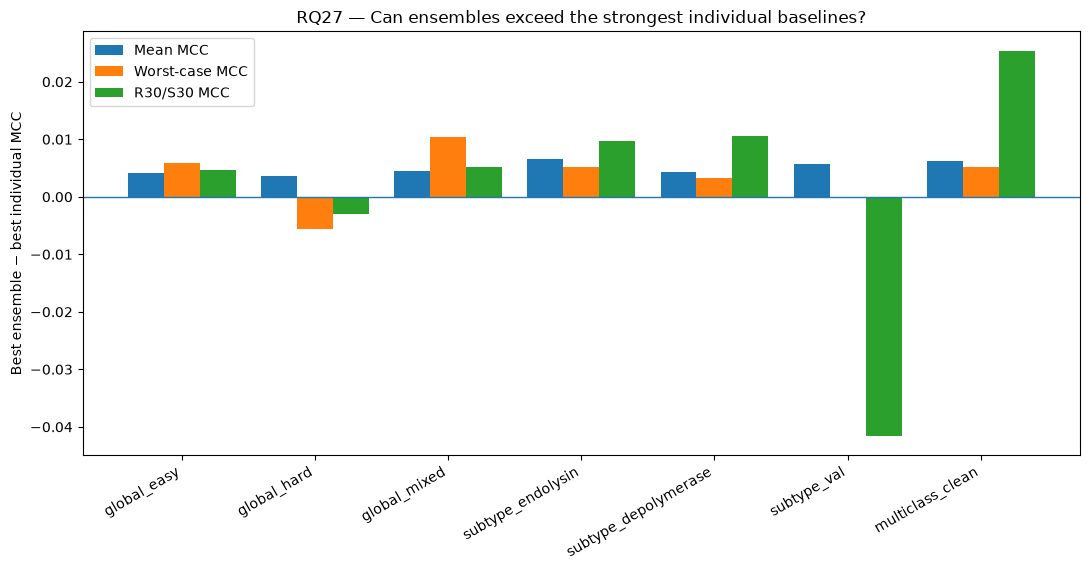

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq27/figures/rq27_max_ensemble_gains_by_task.png


In [15]:

# Figure 1 — maximum ensemble gains by endpoint.
fig_data = task_answer.set_index("task").reindex(TASK_ORDER)

x = np.arange(len(fig_data))
width = 0.27

fig, ax = plt.subplots(figsize=(11.0, 5.8))
ax.bar(
    x - width,
    fig_data["max_mean_gain_vs_best_single"],
    width=width,
    label="Mean MCC",
)
ax.bar(
    x,
    fig_data["max_worst_gain_vs_best_single"],
    width=width,
    label="Worst-case MCC",
)
ax.bar(
    x + width,
    fig_data["max_strict_gain_vs_best_single"],
    width=width,
    label="R30/S30 MCC",
)
ax.axhline(0, linewidth=1)
ax.set_xticks(x, fig_data.index, rotation=30, ha="right")
ax.set_ylabel("Best ensemble − best individual MCC")
ax.set_title("RQ27 — Can ensembles exceed the strongest individual baselines?")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq27_max_ensemble_gains_by_task.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


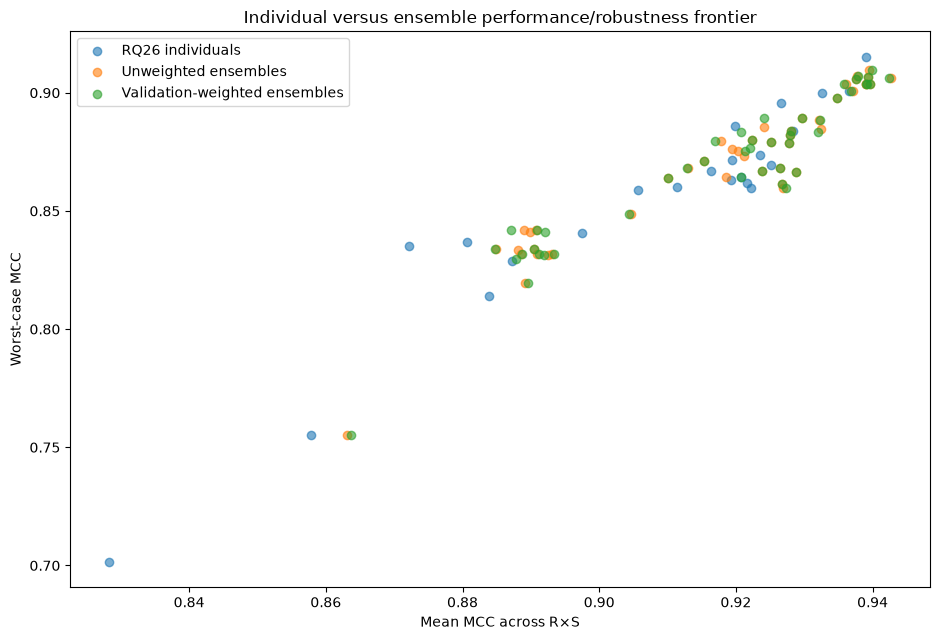

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq27/figures/rq27_individual_vs_ensemble_mean_worst.png


In [16]:

# Figure 2 — mean vs worst-case MCC for individuals and ensembles.
fig, ax = plt.subplots(figsize=(9.5, 6.5))

ax.scatter(
    topk["mean_mcc"],
    topk["worst_mcc"],
    alpha=0.6,
    label="RQ26 individuals",
)

unweighted_profiles = ensemble_comparison[
    ensemble_comparison["voting_scheme"].eq("unweighted_soft")
]
ax.scatter(
    unweighted_profiles["mean_mcc"],
    unweighted_profiles["worst_mcc"],
    alpha=0.6,
    label="Unweighted ensembles",
)

weighted_profiles = ensemble_comparison[
    ensemble_comparison["voting_scheme"].eq("validation_weighted_soft")
]
if len(weighted_profiles):
    ax.scatter(
        weighted_profiles["mean_mcc"],
        weighted_profiles["worst_mcc"],
        alpha=0.6,
        label="Validation-weighted ensembles",
    )

ax.set_xlabel("Mean MCC across R×S")
ax.set_ylabel("Worst-case MCC")
ax.set_title("Individual versus ensemble performance/robustness frontier")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq27_individual_vs_ensemble_mean_worst.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


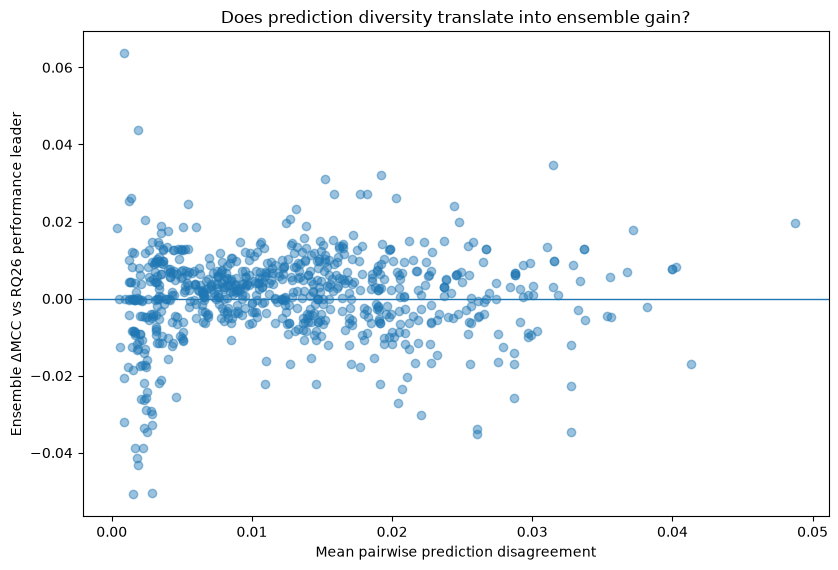

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq27/figures/rq27_complementarity_vs_gain.png


In [17]:

# Figure 3 — complementarity vs matched ensemble gain.
fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.scatter(
    unweighted_cells["mean_pair_disagreement"],
    unweighted_cells["delta_mcc_vs_performance_leader"],
    alpha=0.45,
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Mean pairwise prediction disagreement")
ax.set_ylabel("Ensemble ΔMCC vs RQ26 performance leader")
ax.set_title("Does prediction diversity translate into ensemble gain?")
fig.tight_layout()

path = FIG_DIR / "rq27_complementarity_vs_gain.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


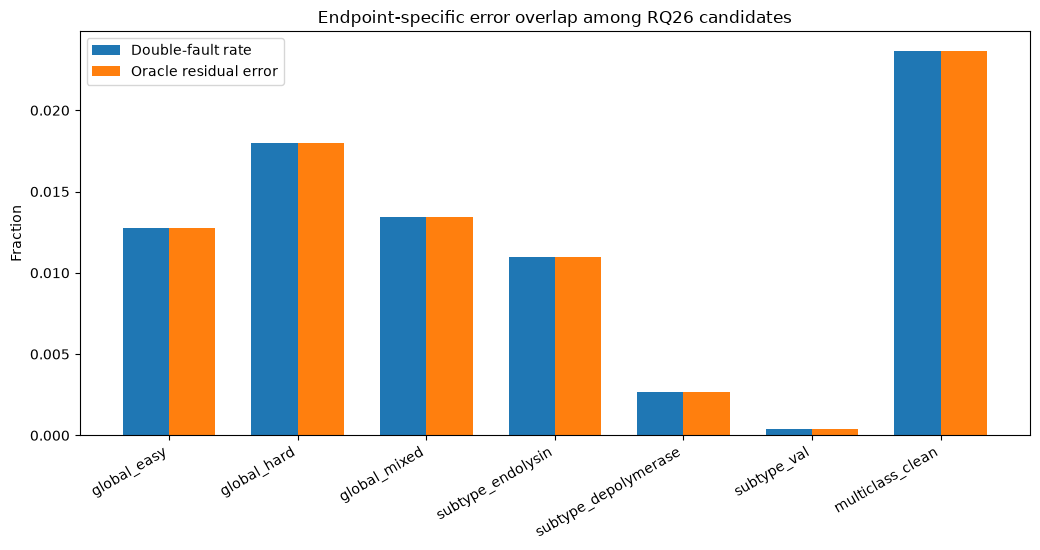

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq27/figures/rq27_pairwise_error_overlap_by_task.png


In [18]:

# Figure 4 — pairwise double-fault and oracle potential by task.
plot = task_complementarity.set_index("task").reindex(TASK_ORDER)

x = np.arange(len(plot))
width = 0.36

fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.bar(
    x - width/2,
    plot["median_double_fault"],
    width=width,
    label="Double-fault rate",
)
ax.bar(
    x + width/2,
    1.0 - plot["median_pair_oracle_accuracy"],
    width=width,
    label="Oracle residual error",
)
ax.set_xticks(x, plot.index, rotation=30, ha="right")
ax.set_ylabel("Fraction")
ax.set_title("Endpoint-specific error overlap among RQ26 candidates")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq27_pairwise_error_overlap_by_task.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


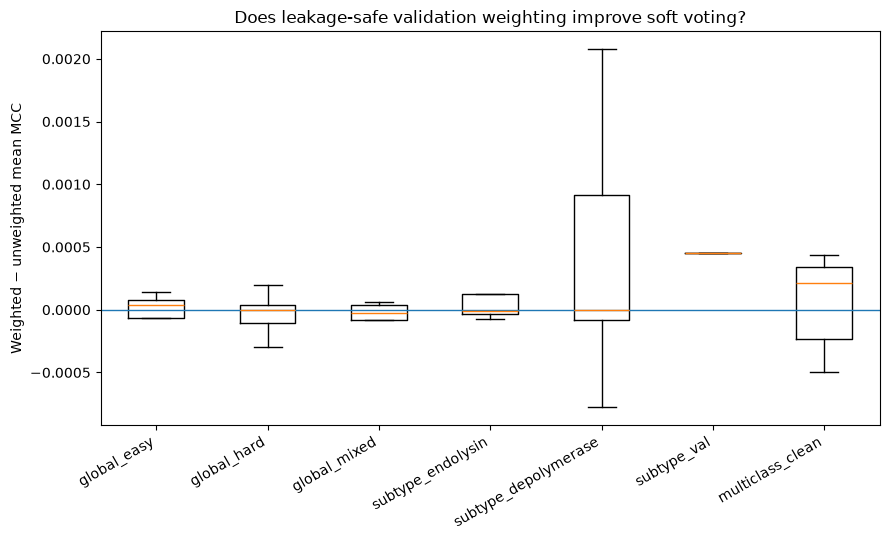

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq27/figures/rq27_weighted_vs_unweighted.png


In [19]:

# Figure 5 — unweighted vs weighted mean-MCC difference when estimable.
weighted_plot = scheme_comparison[
    scheme_comparison["weighted_estimable"]
].copy()

fig, ax = plt.subplots(figsize=(9.0, 5.5))

if len(weighted_plot):
    groups = [
        weighted_plot.loc[
            weighted_plot["task"].eq(task),
            "weighted_minus_unweighted_mean_mcc",
        ].dropna().to_numpy()
        for task in TASK_ORDER
    ]
    ax.boxplot(groups, tick_labels=TASK_ORDER, showfliers=False)
    ax.axhline(0, linewidth=1)
    ax.set_xticklabels(TASK_ORDER, rotation=30, ha="right")
    ax.set_ylabel("Weighted − unweighted mean MCC")
    ax.set_title("Does leakage-safe validation weighting improve soft voting?")
else:
    ax.text(
        0.5, 0.5,
        "Validation-weighted voting not estimable",
        ha="center", va="center",
        transform=ax.transAxes,
    )
    ax.set_axis_off()

fig.tight_layout()

path = FIG_DIR / "rq27_weighted_vs_unweighted.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)



## 15. Interpretation guardrails

RQ27 can support several qualitatively different outcomes.

### Outcome A — ensemble improves average performance

If an ensemble has:

\[
MCC^{ens}_{mean} > \max_i MCC^{single_i}_{mean},
\]

then the selected individual models contain complementary predictive information that survives probability averaging.

### Outcome B — ensemble raises the floor without raising the mean

If mean MCC remains competitive but worst-case MCC increases and/or R/S sensitivity decreases, the ensemble is useful primarily as a **stabilizer**.

### Outcome C — ensemble adds little or nothing

If the best ensembles do not exceed individual mean/worst/strict baselines and candidate errors are highly overlapping, then deployment should prefer the simpler individual model.

That is a scientifically useful result. RQ27 is not designed to force an ensemble win.

### Outcome D — weighting adds no value

Validation-weighted voting may be nearly identical to unweighted voting, especially when all selected members already have strong and similar validation MCC. In that case unweighted soft voting is preferable because it is simpler and less dependent on validation noise.

### Critical caveats

- RQ26 selected candidates using the completed benchmark; RQ27 is therefore **post-benchmark descriptive analysis**, not a pristine held-out model-selection experiment.
- The outer-test set is never used to learn ensemble weights or thresholds.
- A cell-best individual comparator is an outer-test oracle used only as a descriptive upper benchmark.
- VAL remains support-limited; apparent ensemble gains/losses in individual cells should be interpreted with its finite-test uncertainty.
- RQ28, not RQ27, decides whether any ensemble becomes part of the production architecture.


## 16. Export canonical RQ27 artifacts

In [20]:

exports = {
    "rq27_preflight.tsv": preflight,
    "rq27_selected_artifact_audit.tsv": artifact_audit,
    "rq27_validation_weights.tsv": validation_weights,
    "rq27_ensemble_definitions.tsv": ensemble_definitions,
    "rq27_alignment_audit.tsv": alignment_audit,
    "rq27_multiclass_probability_schema_audit.tsv": multiclass_schema_audit,
    "rq27_selected_individual_cells.tsv": individual_cells,
    "rq27_pairwise_error_complementarity.tsv": pairwise_complementarity,
    "rq27_pairwise_complementarity_summary.tsv": pair_summary,
    "rq27_task_complementarity_summary.tsv": task_complementarity,
    "rq27_ensemble_cell_metrics.tsv": ensemble_cells,
    "rq27_ensemble_surface_profiles.tsv": ensemble_profiles,
    "rq27_individual_baselines.tsv": individual_baselines,
    "rq27_ensemble_vs_individual.tsv": ensemble_comparison,
    "rq27_ensemble_role_winners.tsv": ensemble_role_winners,
    "rq27_task_answer.tsv": task_answer,
    "rq27_complementarity_gain_association.tsv": complementarity_gain,
    "rq27_weighted_vs_unweighted.tsv": scheme_comparison,
    "rq27_weighted_vs_unweighted_summary.tsv": scheme_summary,
}

for filename, df in exports.items():
    path = RQ27_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

weighted_profiles_count = int(
    ensemble_profiles["voting_scheme"]
    .eq("validation_weighted_soft").sum()
)

manifest = {
    "rq": "RQ27",
    "question": "can ensembles outperform or stabilize the best individual model?",
    "candidate_source": "frozen RQ26 evidence-adaptive portfolios",
    "n_selected_individual_strategies": int(len(candidate_manifest)),
    "selected_k_by_task": {
        k: int(v) for k, v in k_by_task.to_dict().items()
    },
    "n_unique_ensemble_definitions": int(len(ensemble_definitions)),
    "n_unweighted_ensemble_cell_evaluations": int(
        ensemble_cells["voting_scheme"].eq("unweighted_soft").sum()
    ),
    "n_weighted_ensemble_cell_evaluations": int(
        ensemble_cells["voting_scheme"].eq(
            "validation_weighted_soft"
        ).sum()
    ),
    "n_weighted_surface_profiles": weighted_profiles_count,
    "weighted_model_cell_coverage": weighted_model_cell_coverage,
    "weighted_policy": (
        "nonnegative selected inner-validation MCC; normalized within subset; "
        "outer-test metrics never determine weights"
    ),
    "primary_ensemble": "unweighted_soft_voting",
    "outer_threshold_binary": 0.5,
    "training_performed": False,
    "outer_threshold_optimized": False,
    "outer_weights_optimized": False,
    "bootstrap_performed": False,
    "evaluation_policy": (
        "retrospective post-RQ26 outer-test ensemble analysis; "
        "not an untouched independent final test"
    ),
}

with open(RQ27_OUT / "rq27_manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("Wrote rq27_manifest.json")


Wrote rq27_preflight.tsv: 5 rows
Wrote rq27_selected_artifact_audit.tsv: 368 rows
Wrote rq27_validation_weights.tsv: 368 rows
Wrote rq27_ensemble_definitions.tsv: 46 rows
Wrote rq27_alignment_audit.tsv: 112 rows
Wrote rq27_multiclass_probability_schema_audit.tsv: 64 rows
Wrote rq27_selected_individual_cells.tsv: 368 rows
Wrote rq27_pairwise_error_complementarity.tsv: 448 rows
Wrote rq27_pairwise_complementarity_summary.tsv: 28 rows
Wrote rq27_task_complementarity_summary.tsv: 7 rows
Wrote rq27_ensemble_cell_metrics.tsv: 1472 rows
Wrote rq27_ensemble_surface_profiles.tsv: 92 rows
Wrote rq27_individual_baselines.tsv: 7 rows
Wrote rq27_ensemble_vs_individual.tsv: 92 rows
Wrote rq27_ensemble_role_winners.tsv: 42 rows
Wrote rq27_task_answer.tsv: 7 rows
Wrote rq27_complementarity_gain_association.tsv: 8 rows
Wrote rq27_weighted_vs_unweighted.tsv: 46 rows
Wrote rq27_weighted_vs_unweighted_summary.tsv: 7 rows
Wrote rq27_manifest.json


## 17. Execution gates

In [21]:

required_exports = [
    *exports.keys(),
    "rq27_manifest.json",
]

assert len(master) == 2240
assert len(candidate_manifest) == len(topk)
assert candidate_manifest.groupby("task").size().between(2, 4).all()

assert len(artifact_audit) == len(candidate_manifest) * 16
assert artifact_audit["outer_predictions_exists"].all()

assert len(alignment_audit) == 7 * 16
assert alignment_audit["exact_id_alignment"].all()
assert alignment_audit["exact_y_alignment"].all()

assert len(individual_cells) == len(candidate_manifest) * 16
assert max_mcc_repro_error < 1e-8

assert len(multiclass_schema_audit) == int(
    k_by_task.loc["multiclass_clean"] * 16
)
assert multiclass_schema_audit["argmax_agreement"].ge(0.999999).all()
assert multiclass_schema_audit[
    "canonical_reconstruction_agreement"
].ge(0.999999).all()

assert len(ensemble_definitions) == int(ensemble_defs_by_task.sum())
assert (
    ensemble_cells["voting_scheme"]
    .eq("unweighted_soft").sum()
    == len(ensemble_definitions) * 16
)

assert ensemble_profiles[
    ensemble_profiles["voting_scheme"].eq("unweighted_soft")
].groupby("task").size().eq(ensemble_defs_by_task).all()

assert len(task_answer) == 7
assert len(task_complementarity) == 7

# Weighted results may legitimately be partial or absent, but every weighted
# result that exists must have come from safe validation metrics.
if (
    ensemble_cells["voting_scheme"]
    .eq("validation_weighted_soft").any()
):
    weighted = ensemble_cells[
        ensemble_cells["voting_scheme"]
        .eq("validation_weighted_soft")
    ]
    assert weighted["weights_source"].eq(
        "selected_inner_validation_mcc_nonnegative"
    ).all()

assert all((RQ27_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 5

print("RQ27_EXECUTION_GATES_OK")
print("Selected RQ26 individual strategies:", len(candidate_manifest))
print("Unique ensemble definitions:", len(ensemble_definitions))
print("Expected unweighted ensemble cells:", len(ensemble_definitions) * 16)
print(
    "Observed validation-weighted ensemble cells:",
    int(
        ensemble_cells["voting_scheme"]
        .eq("validation_weighted_soft").sum()
    ),
)
print("Pairwise complementarity rows:", len(pairwise_complementarity))
print("Ensemble surface profiles:", len(ensemble_profiles))
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print()
print(
    "Interpretation status: execution gates passed. "
    "Assign REAL-DATA PASS only after the executed real-project notebook "
    "is inspected for errors, stderr, valid outputs, and scientific coherence."
)


RQ27_EXECUTION_GATES_OK
Selected RQ26 individual strategies: 23
Unique ensemble definitions: 46
Expected unweighted ensemble cells: 736
Observed validation-weighted ensemble cells: 736
Pairwise complementarity rows: 448
Ensemble surface profiles: 92
Exports: 20
Figures: ['rq27_complementarity_vs_gain.png', 'rq27_individual_vs_ensemble_mean_worst.png', 'rq27_max_ensemble_gains_by_task.png', 'rq27_pairwise_error_overlap_by_task.png', 'rq27_weighted_vs_unweighted.png']

Interpretation status: execution gates passed. Assign REAL-DATA PASS only after the executed real-project notebook is inspected for errors, stderr, valid outputs, and scientific coherence.
